# Convex Lightcurve Inversion

Implements the convex inversion approach of Kaasalainen & Torppa (2001):

1. **Forward model**: brightness `L = A @ g` where `g_j` are face areas and `A_ij = S(μ_j, μ0_j)` is the scattering function (linear in `g`).
2. **Exponential parametrisation**: `g_j = exp(a_j)` enforces positivity without explicit constraints.
3. **Inversion**: minimise renormalised χ² over `a_j` with `scipy.optimize.least_squares`.
4. **Reconstruction**: Minkowski minimisation via the dual transform to recover a convex mesh, exported as `.stl`.

In [12]:
try:
    import cupy as cp
    CUPY_AVAILABLE = True
except ImportError:
    CUPY_AVAILABLE = False

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from stl import mesh as stl_mesh

from hac.data import get_model_stl_path, load_data
from hac.constants import CAMERA_ANGLE_ALPHA
from hac.convex_forward import get_unit_vectors#, convex_forward_model_gpu

asteroid = 1
if asteroid == 1:
    R_cylinder = 1.12
elif asteroid == 2:
    R_cylinder = 1.42
elif asteroid == 3:
    R_cylinder = 0.88

## 1. Ellipsoidal shape prior (cylinder-constrained icosphere)

The asteroid is assumed to lie between planes **z = −1** and **z = 1**, with
non-empty intersection with both planes, and to be contained in the cylinder
**D(0, R) × [−1, 1]** where D(0, R) is the disc of radius R in the xy-plane. (Different for each asteroid)

The unit-sphere icosphere is rescaled to the ellipsoid with semi-axes (R, R, 1),
which is the largest body of that family fitting inside the cylinder. Face normals
and areas are recomputed on the scaled surface.

Ellipsoidal prior (R=1.12): 642 vertices, 1280 faces
Total surface area: 14.5804
Vertex ranges — x: [-1.120, 1.120]  y: [-1.120, 1.120]  z: [-1.000, 1.000]


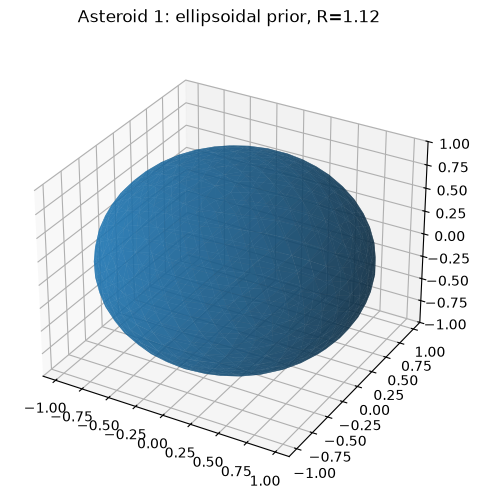

In [13]:
def create_icosphere(subdivisions: int = 2):
    """Geodesic icosphere with `4^subdivisions * 20` faces, all projected to unit sphere."""
    phi = (1 + np.sqrt(5)) / 2
    raw = np.array([
        [-1,  phi, 0], [ 1,  phi, 0], [-1, -phi, 0], [ 1, -phi, 0],
        [ 0, -1,  phi], [ 0,  1,  phi], [ 0, -1, -phi], [ 0,  1, -phi],
        [ phi, 0, -1], [ phi, 0,  1], [-phi, 0, -1], [-phi, 0,  1]
    ], dtype=np.float64)
    verts = list(raw / np.linalg.norm(raw[0]))

    faces = [
        [0,11,5],[0,5,1],[0,1,7],[0,7,10],[0,10,11],
        [1,5,9],[5,11,4],[11,10,2],[10,7,6],[7,1,8],
        [3,9,4],[3,4,2],[3,2,6],[3,6,8],[3,8,9],
        [4,9,5],[2,4,11],[6,2,10],[8,6,7],[9,8,1]
    ]

    def midpoint(p1, p2, cache):
        key = (min(p1, p2), max(p1, p2))
        if key not in cache:
            m = (verts[p1] + verts[p2]) / 2
            m = m / np.linalg.norm(m)
            cache[key] = len(verts)
            verts.append(m)
        return cache[key]

    for _ in range(subdivisions):
        new_faces, cache = [], {}
        for a, b, c in faces:
            ab, bc, ca = midpoint(a,b,cache), midpoint(b,c,cache), midpoint(c,a,cache)
            new_faces += [[a,ab,ca],[b,bc,ab],[c,ca,bc],[ab,bc,ca]]
        faces = new_faces

    V = np.array(verts)
    F = np.array(faces)

    # Face normals and areas
    e1 = V[F[:,1]] - V[F[:,0]]
    e2 = V[F[:,2]] - V[F[:,0]]
    cross = np.cross(e1, e2)
    mag   = np.linalg.norm(cross, axis=1)
    face_normals = cross / mag[:, None]
    face_areas   = 0.5 * mag
    return V, F, face_normals, face_areas


sphere_verts, sphere_faces, normals, sigma = create_icosphere(subdivisions=3)

# --- Cylinder prior: scale unit sphere to ellipsoid with semi-axes (R, R, 1) ---
# Object is assumed inside D(0, R) x [-1, 1] with non-empty intersection at z=±1.

scale_xyz  = np.array([R_cylinder, R_cylinder, 1.0])
sphere_verts = sphere_verts * scale_xyz[None, :]

# Recompute normals and areas on the scaled ellipsoidal surface
_e1 = sphere_verts[sphere_faces[:, 1]] - sphere_verts[sphere_faces[:, 0]]
_e2 = sphere_verts[sphere_faces[:, 2]] - sphere_verts[sphere_faces[:, 0]]
_cross = np.cross(_e1, _e2)
_mag   = np.linalg.norm(_cross, axis=1)
normals = _cross / _mag[:, None]
sigma   = 0.5 * _mag

n_facets = len(normals)
print(f"Ellipsoidal prior (R={R_cylinder}): {len(sphere_verts)} vertices, {n_facets} faces")
print(f"Total surface area: {sigma.sum():.4f}")
print(f"Vertex ranges — x: [{sphere_verts[:,0].min():.3f}, {sphere_verts[:,0].max():.3f}]  "
      f"y: [{sphere_verts[:,1].min():.3f}, {sphere_verts[:,1].max():.3f}]  "
      f"z: [{sphere_verts[:,2].min():.3f}, {sphere_verts[:,2].max():.3f}]")

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot_trisurf(sphere_verts[:,0], sphere_verts[:,1], sphere_verts[:,2], triangles=sphere_faces, alpha=0.7,
                edgecolor="none")
ax.set_xlim(-R_cylinder, R_cylinder); ax.set_ylim(-R_cylinder, R_cylinder); ax.set_zlim(-1, 1)

fig.suptitle(f"Asteroid {asteroid}: ellipsoidal prior, R={R_cylinder}")
plt.tight_layout()
plt.show()

## 2. Load observed lightcurve

In [14]:
ds_blender = load_data(asteroid, "simulated", "intensity")
cam_keys   = list(CAMERA_ANGLE_ALPHA.keys())
n_cams     = len(cam_keys)
n_phases   = 360
phases     = np.linspace(0, 2 * np.pi, n_phases, endpoint=False)

e_sun          = np.array([-1.0, 0.0, 0.0])
lambert_weight = 0.5   # LSL: S = mu*mu0/(mu+mu0) + lw*mu*mu0

obs_norm = np.empty((n_cams, n_phases))
for i, cam in enumerate(cam_keys):
    lc = ds_blender.data[cam].values.astype(np.float64)
    obs_norm[i] = lc# / lc.mean() # skip normalization since this is already done

print(f"Observations: {n_cams} cameras × {n_phases} phases = {n_cams * n_phases} data points")

Observations: 28 cameras × 360 phases = 10080 data points


## 3. Build forward matrix A

`A[i·n_phases + t, j] = S(μ_j(t), μ0_j(t))` — scattering contribution of facet `j`
at rotation phase `t` for camera `i`. With fixed normals, brightness is **linear** in `g`.

In [ ]:
cos_p = np.cos(phases)  
sin_p = np.sin(phases)

A_blocks = []
for cam in cam_keys:
    phi_deg   = float(cam.split("_")[0])
    alpha_deg = CAMERA_ANGLE_ALPHA[cam]
    _, e_obs  = get_unit_vectors(phi_deg, alpha_deg)
    e_obs     = np.asarray(e_obs, dtype=np.float64)

    # Rotate sun & observer through rotational phase (z-axis rotation)
    e_sun_rot = np.column_stack([
        cos_p * e_sun[0] - sin_p * e_sun[1],
        sin_p * e_sun[0] + cos_p * e_sun[1],
        np.full(n_phases, e_sun[2])
    ])  # (n_phases, 3)
    e_obs_rot = np.column_stack([
        cos_p * e_obs[0] - sin_p * e_obs[1],
        sin_p * e_obs[0] + cos_p * e_obs[1],
        np.full(n_phases, e_obs[2])
    ])  # (n_phases, 3)

    mu0  = e_sun_rot @ normals.T   # (n_phases, n_facets)
    mu   = e_obs_rot @ normals.T   # (n_phases, n_facets)
    mask = (mu0 > 0) & (mu > 0)

    # LSL scattering law (eq. 2 of doi:10.48550/arXiv.2502.16455)
    # np.maximum avoids 0/0 when both mu and mu0 are zero (mask=False there anyway)
    S = np.where(mask, mu * mu0 / np.maximum(mu + mu0, 1e-30) + lambert_weight * mu * mu0, 0.0)
    A_blocks.append(S)

A      = np.vstack(A_blocks)              # (n_cams * n_phases, n_facets)
A_3d   = A.reshape(n_cams, n_phases, n_facets)
A_mean = A_3d.mean(axis=1)               # (n_cams, n_facets)  — per-camera mean

print(f"Forward matrix A: {A.shape}  ({A.nbytes / 1e6:.1f} MB)")

Forward matrix A: (10080, 1280)  (103.2 MB)


## 4. Least-squares inversion

Minimise the normalised χ²:
$$\chi^2_{\rm ren} = \sum_i \left\|\frac{L^{(i)}}{\bar L^{(i)}} - \frac{A^{(i)}\mathbf{g}}{\overline{A^{(i)}\mathbf{g}}}\right\|^2, \quad g_j = e^{a_j}$$

In [ ]:
optimizer = "cg"

# Move matrices to GPU once; fall back to NumPy if CuPy is unavailable.
if CUPY_AVAILABLE:
    _xp       = cp
    _A        = cp.asarray(A)
    _A_3d     = cp.asarray(A_3d)
    _A_mean   = cp.asarray(A_mean)
    _obs_norm = cp.asarray(obs_norm)
else:
    _xp       = np
    _A        = A
    _A_3d     = A_3d
    _A_mean   = A_mean
    _obs_norm = obs_norm
    print("CuPy unavailable — using NumPy CPU backend")

_use_gpu = (_xp is not np)


def matrix_residuals_and_jac(a):
    """Full residual vector + Jacobian for Levenberg–Marquardt.

    Memory: O(n_obs × n_facets) — avoid for n_facets ≳ 500.
    """
    g    = _xp.exp(_xp.asarray(a))
    Ag   = _A @ g                                        # (n_cams * n_phases,)
    Ag3d = Ag.reshape(n_cams, n_phases)
    m    = Ag3d.mean(axis=1)                             # (n_cams,)

    norm_model = Ag3d / m[:, None]
    res        = _obs_norm - norm_model

    J = -(g[None, None, :] / m[:, None, None]) * (
        _A_3d - norm_model[:, :, None] * _A_mean[:, None, :]
    )  # (n_cams, n_phases, n_facets)

    if _use_gpu:
        return res.ravel().get(), J.reshape(n_cams * n_phases, n_facets).get()
    return res.ravel(), J.reshape(n_cams * n_phases, n_facets)


def cost_and_grad(a):
    """Scalar cost + gradient for L-BFGS / CG.

    Computes J^T r without ever materialising the full (n_obs × n_facets)
    Jacobian.  Memory stays O(n_obs + n_facets) regardless of n_facets.

    Derivation:
      f = 0.5 ||r||^2,   r[i,t] = obs[i,t] - Ag[i,t]/m_i
      df/da_k = -g_k * ( term1[k] - term2[k] )
        term1[k] = Σ_{i,t} (r[i,t]/m_i) * A[i·T+t, k]   = A.T @ (r/m).ravel()
        term2[k] = Σ_i A_mean[i,k] * Σ_t r[i,t]·nm[i,t] / m_i
    """
    g    = _xp.exp(_xp.asarray(a, dtype=_xp.float64))
    Ag   = _A @ g
    Ag3d = Ag.reshape(n_cams, n_phases)
    m    = Ag3d.mean(axis=1)

    norm_model = Ag3d / m[:, None]
    res        = _obs_norm - norm_model                  # (n_cams, n_phases)

    cost = float(0.5 * _xp.dot(res.ravel(), res.ravel()))
    if _use_gpu and hasattr(cost, 'get'):
        cost = cost.get()

    term1 = _A.T @ (res / m[:, None]).ravel()           # (n_facets,)
    term2 = _A_mean.T @ (_xp.sum(norm_model * res, axis=1) / m)  # (n_facets,)
    grad  = -g * (term1 - term2)

    if _use_gpu:
        return float(cost), grad.get().astype(np.float64)
    return float(cost), np.asarray(grad, dtype=np.float64)


# ---------------------------------------------------------------------------
# Run inversion
# ---------------------------------------------------------------------------
from scipy.optimize import least_squares, minimize

a_init = np.log(sigma)   # warm start: ellipsoidal prior face areas

if optimizer == "lm":
    print(f"Running Levenberg–Marquardt  (n_params={n_facets})...")
    result = least_squares(
        lambda a: matrix_residuals_and_jac(a)[0],
        a_init,
        jac=lambda a: matrix_residuals_and_jac(a)[1],
        method="lm",
        ftol=1e-10, xtol=1e-10,
        max_nfev=1000,
        verbose=2,
    )
    a_opt = result.x
    print(f"\n{result.message}")
    print(f"Cost: {result.cost:.6f}")

elif optimizer in ("lbfgs", "cg"):
    sci_method = {"lbfgs": "L-BFGS-B", "cg": "CG"}[optimizer]
    print(f"Running {sci_method}  (n_params={n_facets})...")

    _iter = [0]
    def _cb(a):
        _iter[0] += 1
        if _iter[0] % 25 == 0:
            c, _ = cost_and_grad(a)
            print(f"  iter {_iter[0]:4d}: cost = {c:.6f}")

    result = minimize(
        cost_and_grad,
        a_init,
        jac=True,          # function returns (f, grad) tuple
        method=sci_method,
        callback=_cb,
        options={"maxiter": 2000, "gtol": 1e-9},
    )
    a_opt = result.x
    print(f"\n{result.message}")
    print(f"Cost: {result.fun:.6f}")

else:
    raise ValueError(f"Unknown optimizer {optimizer!r}. Choose 'lm', 'lbfgs', or 'cg'.")

g_opt = np.exp(a_opt)
print(f"g_j:  min={g_opt.min():.4f}  max={g_opt.max():.4f}  mean={g_opt.mean():.4f}")

conv_vec = normals.T @ g_opt
print(f"Convexity residual |Σ n_j g_j| / Σ g_j = {np.linalg.norm(conv_vec)/g_opt.sum():.4e}")

Running CG  (n_params=1280)...
  iter   25: cost = 3.631813
  iter   50: cost = 3.254510
  iter   75: cost = 3.120129
  iter  100: cost = 3.034063
  iter  125: cost = 2.958708
  iter  150: cost = 2.933045
  iter  175: cost = 2.901765
  iter  200: cost = 2.884650
  iter  225: cost = 2.877595
  iter  250: cost = 2.867590
  iter  275: cost = 2.859926
  iter  300: cost = 2.821032
  iter  325: cost = 2.817561
  iter  350: cost = 2.814117
  iter  375: cost = 2.799798
  iter  400: cost = 2.795308
  iter  425: cost = 2.791464
  iter  450: cost = 2.788952
  iter  475: cost = 2.786301
  iter  500: cost = 2.783428
  iter  525: cost = 2.781370
  iter  550: cost = 2.777043
  iter  575: cost = 2.767745
  iter  600: cost = 2.762946
  iter  625: cost = 2.761865
  iter  650: cost = 2.760342
  iter  675: cost = 2.758680
  iter  700: cost = 2.757916
  iter  725: cost = 2.753985
  iter  750: cost = 2.753392
  iter  775: cost = 2.752839
  iter  800: cost = 2.742958
  iter  825: cost = 2.741467
  iter  850:

## 5. Lightcurve fit quality

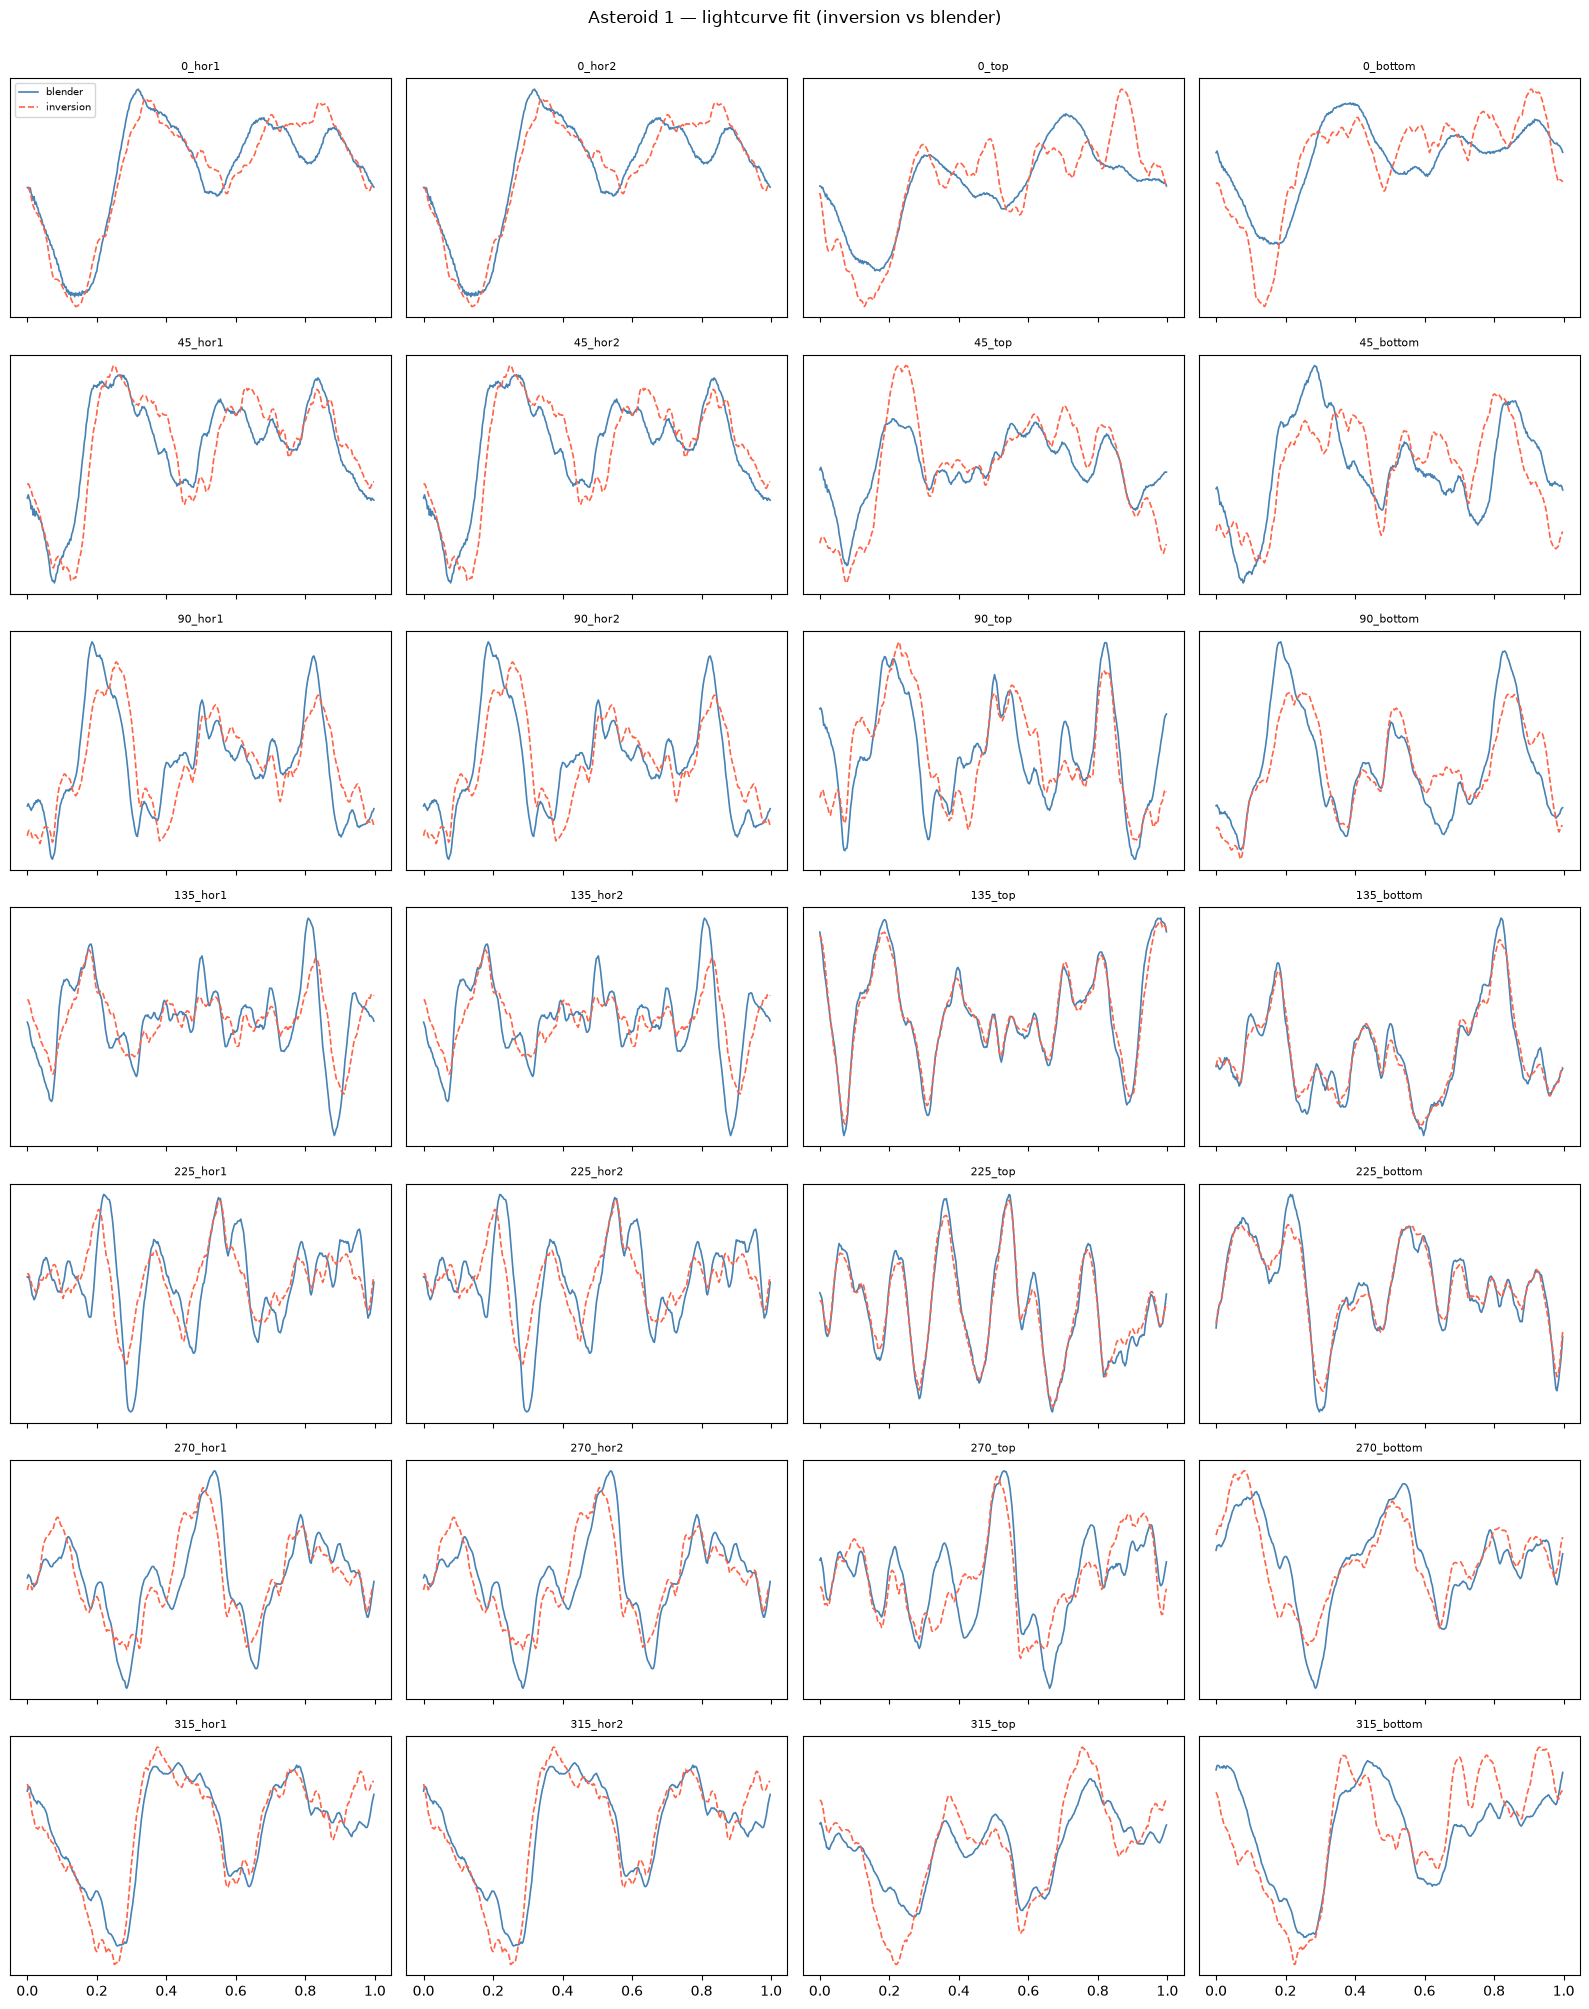

Overall MSE (normalised): 0.000538


In [17]:
Ag_opt     = (A @ g_opt).reshape(n_cams, n_phases)
pred_norm  = Ag_opt / Ag_opt.mean(axis=1, keepdims=True)
phase_axis = np.linspace(0, 1, n_phases, endpoint=False)

fig, axes = plt.subplots(7, 4, figsize=(16, 20), sharex=True)
for ax, cam, i in zip(axes.ravel(), cam_keys, range(n_cams)):
    ax.plot(phase_axis, obs_norm[i],  lw=1.2, color="steelblue", label="blender")
    ax.plot(phase_axis, pred_norm[i], lw=1.2, color="tomato",    label="inversion", ls="--")
    ax.set_title(cam, fontsize=8)
    ax.set_yticks([])

axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Asteroid {asteroid} — lightcurve fit (inversion vs blender)", y=1.002)
fig.tight_layout()
plt.show()

print(f"Overall MSE (normalised): {np.mean((obs_norm - pred_norm)**2):.6f}")

## 6. Shape reconstruction via Minkowski minimisation

Given face normals `n_j` and target areas `g_j`, find face-plane distances `l_j`
such that the convex polyhedron `{x : n_j·x ≤ l_j}` has those face areas.

**Dual transform** (Appendix C in Kaasalainen & Torppa (2001)): dual vertex `v_j = n_j/l_j`; convex hull of `{v_j}`
gives primal vertices `p_k = m_k/d_k` (dual face normal / distance).
The face area for normal `n_j` equals the area of the polygon formed by primal vertices
belonging to dual faces that contain vertex `j`.

**Iteration**: projected gradient ascent on `V(l)` with `grad V = A` (face areas).

**Optional Cylinder constraint**: the body must lie inside D(0, R) × [−1, 1].
For a convex body, this is equivalent to bounding its support function:
$$h(\mathbf{n}) \leq h_{\rm cyl}(\mathbf{n}) = R\sqrt{n_x^2+n_y^2} + |n_z|$$
since $h_{\rm cyl}$ is the support function of the bounding cylinder.
After each gradient step (and after the scale renormalisation) every $l_j$ is
clipped to $[10^{-6},\, h_{\rm cyl}(\mathbf{n}_j)]$, keeping the iterates inside
the feasible set.

In [18]:
def _polygon_area_3d(verts: np.ndarray, normal: np.ndarray) -> float:
    """Area of a convex polygon in 3-D via 2-D convex hull."""
    n_hat = normal / np.linalg.norm(normal)
    ref   = np.array([1., 0., 0.]) if abs(n_hat[0]) < 0.9 else np.array([0., 1., 0.])
    u = np.cross(n_hat, ref);  u /= np.linalg.norm(u)
    v = np.cross(n_hat, u)
    p2d = verts @ np.column_stack([u, v])
    try:
        return ConvexHull(p2d).volume   # 2-D: .volume = area
    except Exception:
        return 0.0


def face_areas_from_l(normals: np.ndarray, l: np.ndarray) -> np.ndarray:
    """
    Primal face areas for a convex polyhedron with normals `normals` and
    face-plane distances `l` from the origin.
    Uses the dual transform of Appendix C (Kaasalainen & Torppa 2001).
    """
    n = len(normals)
    dual_verts = normals / l[:, None]  # (n, 3)
    try:
        hull_d = ConvexHull(dual_verts)
    except Exception:
        return np.zeros(n)

    # Primal vertex for each dual simplex: p_k = m_k / d_k
    eq   = hull_d.equations                       # (n_simplices, 4)
    d_k  = -eq[:, 3]                              # > 0 for outward-facing normals
    pv   = eq[:, :3] / d_k[:, None]              # (n_simplices, 3) — primal vertices
    simp = hull_d.simplices                       # (n_simplices, 3)
    hull_vset = set(hull_d.vertices)

    areas = np.zeros(n)
    for j in range(n):
        if j not in hull_vset:
            continue
        member = np.any(simp == j, axis=1)
        face_pv = pv[member]                       # primal verts of this face
        if len(face_pv) >= 3:
            areas[j] = _polygon_area_3d(face_pv, normals[j])
    return areas


def minkowski_minimize(
    normals: np.ndarray,
    g_target: np.ndarray,
    n_iter: int = 400,
    alpha: float = 0.05,
    l_max: np.ndarray | None = None,
    verbose: bool = True,
) -> np.ndarray:
    """Projected gradient ascent to find l such that face areas match g_target.

    l_max : per-facet upper bound on l (support function of bounding cylinder).
            After each gradient step and after scale renormalisation l is clipped
            to [1e-6, l_max], keeping iterates inside the feasible set.
    """
    n  = len(normals)
    l  = np.full(n, np.dot(g_target, g_target) / g_target.sum())
    if l_max is not None:
        l = np.minimum(l, l_max)
    c  = np.dot(l, g_target)
    g2 = np.dot(g_target, g_target)

    for it in range(n_iter):
        areas = face_areas_from_l(normals, l)
        err   = np.linalg.norm(areas - g_target) / (np.linalg.norm(g_target) + 1e-12)
        if verbose and it % 50 == 0:
            print(f"  iter {it:4d}: relative area error = {err:.4f}")
        if err < 1e-4:
            print(f"  Converged at iter {it}")
            break

        # Projected gradient of V w.r.t. l  (eq. 18 in paper)
        proj = areas - np.dot(areas, g_target) / g2 * g_target
        l    = np.maximum(l + alpha * proj, 1e-6)
        if l_max is not None:
            l = np.minimum(l, l_max)          # enforce cylinder bound
        l   *= c / np.dot(l, g_target)        # scale renormalisation
        if l_max is not None:
            l = np.minimum(l, l_max)          # re-enforce after rescaling

    final_err = np.linalg.norm(face_areas_from_l(normals, l) - g_target) / np.linalg.norm(g_target)
    print(f"  Final relative area error: {final_err:.4f}")
    return l

In [20]:
# Support function of the bounding cylinder D(0, R) x [-1, 1]:
#   h_cyl(n) = R * sqrt(nx^2 + ny^2) + |nz|
h_cyl = R_cylinder * np.sqrt(normals[:, 0]**2 + normals[:, 1]**2) + np.abs(normals[:, 2])

print("Running Minkowski minimisation")
#l_opt = minkowski_minimize(normals, g_opt, n_iter=1000, alpha=0.05, l_max=h_cyl, verbose=True)
l_opt = minkowski_minimize(normals, g_opt, n_iter=1000, alpha=0.05, l_max=None, verbose=True)

Running Minkowski minimisation
  iter    0: relative area error = 0.9976
  iter   50: relative area error = 0.9933
  iter  100: relative area error = 0.9913
  iter  150: relative area error = 0.9903
  iter  200: relative area error = 0.9896
  iter  250: relative area error = 0.9891
  iter  300: relative area error = 0.9886
  iter  350: relative area error = 0.9882
  iter  400: relative area error = 0.9878
  iter  450: relative area error = 0.9874
  iter  500: relative area error = 0.9871
  iter  550: relative area error = 0.9868
  iter  600: relative area error = 0.9865
  iter  650: relative area error = 0.9862
  iter  700: relative area error = 0.9859
  iter  750: relative area error = 0.9857
  iter  800: relative area error = 0.9855
  iter  850: relative area error = 0.9852
  iter  900: relative area error = 0.9850
  iter  950: relative area error = 0.9848
  Final relative area error: 0.9846


## 7. Extract mesh and export as STL

In [ ]:
def l_to_convex_mesh(normals: np.ndarray, l: np.ndarray):
    """
    Reconstruct vertices and triangulated faces of the convex polyhedron
    using the dual transform. Returns (vertices, faces) as numpy arrays.
    """
    dual_verts = normals / l[:, None]
    hull_d     = ConvexHull(dual_verts)

    eq  = hull_d.equations
    d_k = -eq[:, 3]
    pv  = eq[:, :3] / d_k[:, None]   # primal vertices

    hull_p = ConvexHull(pv)
    # Re-index to only used vertices
    used   = hull_p.vertices
    idx    = {old: new for new, old in enumerate(used)}
    verts  = pv[used]
    faces  = np.array([[idx[v] for v in s] for s in hull_p.simplices])
    return verts, faces


def save_stl(verts: np.ndarray, faces: np.ndarray, path: str) -> None:
    """Save a mesh as binary STL using numpy-stl."""
    m = stl_mesh.Mesh(np.zeros(len(faces), dtype=stl_mesh.Mesh.dtype))
    for i, f in enumerate(faces):
        m.vectors[i] = verts[f]
    m.save(path)

recon_verts, recon_faces = l_to_convex_mesh(normals, l_opt)
print(f"Reconstructed mesh: {len(recon_verts)} vertices, {len(recon_faces)} faces")

out_stl = f"recons/asteroid{asteroid}_recon_faces_{len(recon_faces)}.stl"
save_stl(recon_verts, recon_faces, out_stl)
print(f"Saved to {out_stl}")

Reconstructed mesh: 2262 vertices, 4520 faces
Saved → /zhome/95/1/155570/HAC-DTU/workspaces/christian/recons/asteroid1_recon_faces_4520.stl


## 8. Visualise reconstructed shape vs ground truth

Scale = 56.280458444675666
Volume (true): 235.85   (recon, scaled): 235.85


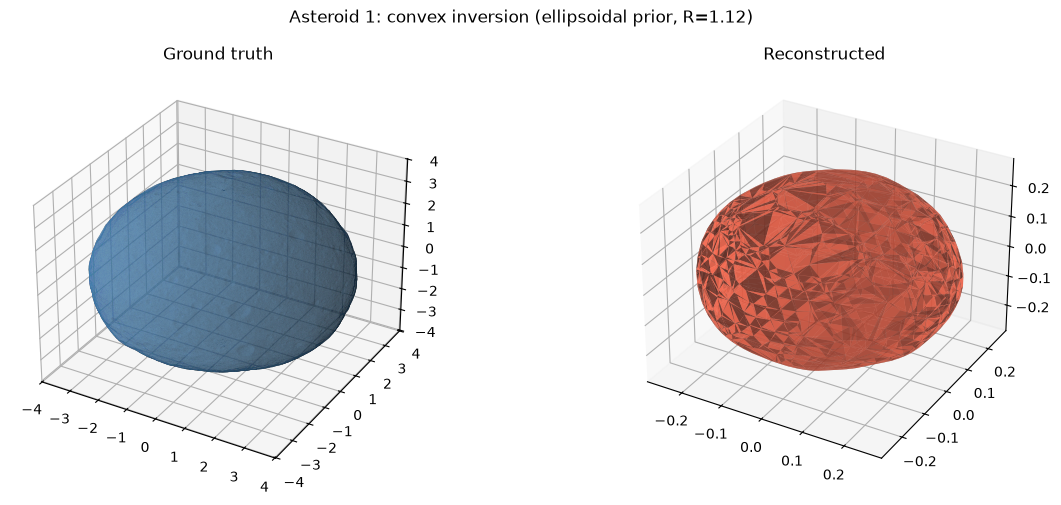

In [22]:
# Load true mesh with numpy-stl
true_raw = stl_mesh.Mesh.from_file(str(get_model_stl_path(asteroid)))
true_verts_all = true_raw.vectors.reshape(-1, 3)
true_faces_idx = np.arange(len(true_verts_all)).reshape(-1, 3)

# Scale reconstructed mesh to match true mesh volume for fair comparison
def mesh_volume_from_faces(verts, faces):
    v0 = verts[faces[:, 0]]
    v1 = verts[faces[:, 1]]
    v2 = verts[faces[:, 2]]
    return np.abs(np.sum(v0 * np.cross(v1, v2)) / 6.0)

vol_true  = mesh_volume_from_faces(true_verts_all, true_faces_idx)
vol_recon = mesh_volume_from_faces(recon_verts, recon_faces)
scale     = (vol_true / vol_recon) ** (1 / 3)
print(f"Scale = {scale}")
rv_scaled = recon_verts * scale
print(f"Volume (true): {vol_true:.2f}   (recon, scaled): {vol_recon * scale**3:.2f}")

fig = plt.figure(figsize=(13, 5))
for col, (title, V, F, c) in enumerate([
    ("Ground truth",  true_verts_all, true_faces_idx, "steelblue"),
    ("Reconstructed", recon_verts,       recon_faces,    "tomato"),
]):
    ax = fig.add_subplot(1, 2, col + 1, projection="3d")
    ax.plot_trisurf(V[:,0], V[:,1], V[:,2], triangles=F, alpha=0.7,
                    edgecolor="none", color=c)
    lim = max(np.abs(V).max(), 0.1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_title(title)

fig.suptitle(f"Asteroid {asteroid}: convex inversion (ellipsoidal prior, R={R_cylinder})")
plt.tight_layout()
plt.show()